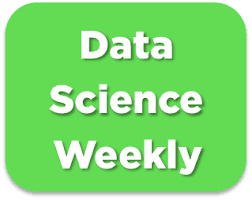

# Import libraries

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.metrics import r2_score
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)
from sklearn.model_selection import cross_val_score

import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings(
    "ignore", category=DeprecationWarning
)  # to avoid deprecation warnings

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

from IPython.display import display

# Read file with labels

In [2]:
df = pd.read_csv("walmart_sales.csv")

# Preprocessing

## preprocessing pandas

In [3]:
df.columns = df.columns.str.lower()
print(df.columns)

Index(['store', 'date', 'weekly_sales', 'holiday_flag', 'temperature',
       'fuel_price', 'cpi', 'unemployment'],
      dtype='str')


### Missing values

In [4]:
print('Missing values treatment...')
cols = ['weekly_sales', 'date']
df = df.dropna(subset=cols) # drop lines where target values is missing. 

categories = ['store', 'holiday_flag']
df[categories] = df[categories].astype('Int64') # convert categories in integers, avoid error "Cannot convert non-finite values".
print(df.dtypes)

Missing values treatment...
store             Int64
date                str
weekly_sales    float64
holiday_flag      Int64
temperature     float64
fuel_price      float64
cpi             float64
unemployment    float64
dtype: object


### Convert data

In [5]:
# Conversion des dates au format date time
type('date')
df['date'] = pd.to_datetime(df['date'], format = "%d-%m-%Y")
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['weekday'] = df['date'].dt.dayofweek
print(df['weekday'].value_counts(dropna=False))

weekday
4    118
Name: count, dtype: int64


In [6]:
numerical_cols = ['fuel_price', 'cpi', 'unemployment']
df[numerical_cols] = df[numerical_cols].round(2)
print(df[categories + ['date']].dtypes)

store                    Int64
holiday_flag             Int64
date            datetime64[us]
dtype: object


In [7]:
df=df.drop(['date', 'day', 'weekday'], axis=1)
df.head(1)

,store,weekly_sales,holiday_flag,temperature,fuel_price,cpi,unemployment,year,month
0,6,1572117.54,<NA>,59.61,3.04,214.78,6.86,2011,2


### mask outlyers

In [8]:
mean = df['unemployment'].mean()
sigma = df['unemployment'].std()

mask = df['unemployment'].between(mean - 3 * sigma, mean + 3 * sigma)
df = df[mask]
print(df.shape)

(102, 9)


# Baseline model

## preprocessing en sklearn

### Multivariate linear regression

#### Separate target variable Y from features X

In [9]:
# Separate target variable Y from features X

print("Separating labels from features...")
target = 'weekly_sales'

y = df.loc[:, target]# or df.iloc[:, -1] # or  df.loc[:, df.columns == target]
X = df.drop(target, axis=1) # or df.iloc[:, 0:-1]  # All columns are kept, except the target
# or df.loc[:, df.columns != target]
print("...Done.")

print("y : ")
print(y.head())
print()
print("X : ")
print(X.head())

Separating labels from features...
...Done.
y : 
0    1572117.54
1    1807545.43
4    1644470.66
5    1857533.70
6     695396.19
Name: weekly_sales, dtype: float64

X : 
   store  holiday_flag  temperature  fuel_price     cpi  unemployment  year  \
0      6          <NA>        59.61        3.04  214.78          6.86  2011   
1     13             0        42.38        3.44  128.62          7.47  2011   
4      6             0        78.89        2.76  212.41          7.09  2010   
5      4             0          NaN        2.76  126.16          7.90  2010   
6     15             0        69.80        4.07  134.86          7.66  2011   

   month  
0      2  
1      3  
4      5  
5      5  
6      6  


In [10]:
'''# Automatically detect names of numeric/categorical columns
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

print("Found numeric features ", numeric_features)
print("Found categorical features ", categorical_features)'''

'# Automatically detect names of numeric/categorical columns\nnumeric_features = X.select_dtypes(include="number").columns.tolist()\ncategorical_features = X.select_dtypes(exclude="number").columns.tolist()\n\nprint("Found numeric features ", numeric_features)\nprint("Found categorical features ", categorical_features)'

In [11]:
numeric_features = ['temperature', 'fuel_price', 'cpi', 'unemployment', 'year']
categorical_features = ['store', 'holiday_flag', 'month']

Remember to treat year, 'month', 'day', 'weekday' as numeric features (cf instructions)

#### Divide dataset train set & test set 

We apply different transformations to the features, depending on their types. Numeric columns will be standardized whereas categorical columns will be one-hot-encoded. As regards missing values imputation, it can apply to every column, but different rules may be used. 

In [12]:
# Divide dataset Train set & Test set
print("Dividing into train and test sets...")
# WARNING : don't forget stratify=Y for classification problems
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("...Done.")
print()

Dividing into train and test sets...
...Done.



We'll use simple imputer because we don't have any missing values. num_imputer = SimpleImputer(strategy="median")

We normalize numeric colomns to scale them down.

#### pipelines

In [13]:
print("Preprocessing X_train...")
print(X_train.head())
print()

# categoric

cat_transformer = Pipeline(steps=[
    ('cat_imputer', SimpleImputer(strategy="most_frequent")),
    ('catEncoder', OneHotEncoder(drop='if_binary'))
])
# numerical

num_transformer = Pipeline(steps=[
    ('num_imputer', SimpleImputer(strategy="median")),
    ('scaler', StandardScaler())
])

Preprocessing X_train...
     store  holiday_flag  temperature  fuel_price     cpi  unemployment  year  \
67       3             0        45.71        2.57  214.42          7.37  2010   
28      17             0        45.22        2.92  126.56          6.64  2010   
98      10             0        90.32         NaN  126.13          9.52  2010   
55      13             0        63.60        3.65  129.52          6.88  2011   
143      3             0        78.53        2.70  214.50          7.34  2010   

     month  
67       2  
28       4  
98       6  
55       9  
143      6  



In [14]:
#### pipeline global
print("Encoding categorical features and standardizing numerical features...")

preprocessor = ColumnTransformer(transformers=[
    ('cat_transformer', cat_transformer, categorical_features),
    ('num_transformer', num_transformer, numeric_features)
])

# Preprocessings on train set
print("Preprocessing sur le train set...")
X_train = preprocessor.fit_transform(X_train)
print('...Terminé.')
X_train[0:5] # MUST use this syntax because X_train is a numpy array and not a pandas DataFrame anymore
print()


Encoding categorical features and standardizing numerical features...
Preprocessing sur le train set...
...Terminé.



Nous n'utilisons pas labelEncoder sur y_test car les labels sont déjà convertis sur converted

#### Test pipeline

In [15]:
# Preprocessings sur le test set
print("Preprocessing on test set...")
X_test = preprocessor.transform(X_test) # Don't fit again !! The test set is used for validating decisions
# we made based on the training set, therefore we can only apply transformations that were parametered using the training set.
# Otherwise this creates what is called a leak from the test set which will introduce a bias in all your results.
print('...Done.')
X_test[:5, :] # MUST use this syntax because X_test is a numpy array and not a pandas DataFrame anymore

Preprocessing on test set...
...Done.


<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 35 stored elements and shape (5, 37)>

#### Train model

In [16]:

from sklearn.linear_model import LinearRegression

print("Train model...")
baseline = LinearRegression() # 
baseline.fit(X_train, y_train)
print("...Done.")

Train model...
...Done.


#### Performance evaluation

#### Predictions

In [17]:
# Predictions on training set
print("Predictions on training set...")
y_train_pred = baseline.predict(X_train)
print("...Done.")
print(y_train_pred)
print()

Predictions on training set...
...Done.
[ 547890.84826656  795626.99993472 1769077.85381531 1876635.58211736
  372413.8128039   239108.5327116   447049.96294828  578760.29699069
 1621951.82040858  270719.8396941  1546332.53259303 1319653.18159891
 2416872.3448361  1041209.3977947   481896.78293979 2084704.77928861
 1443478.21880738 2035903.73167755 2056865.96526699 1083375.7021519
 2053481.94378886 1470527.42280502 1055812.41215018 1927538.37386373
 2458400.63524621  280064.29282452  881989.19471028  891354.57697529
 2032705.28340943 2030681.8532416  1867927.06407493 2322083.04608374
  548498.8963615  1888425.95216431 1402114.72919397 1528159.63389979
  455179.15922922 1757242.90611596  840418.48941076 1576610.68356861
  315472.64988682  509045.79452895 1586525.47139619  584188.39935983
 1550959.42572163  330931.844556   1924497.14593263 1555281.21441732
  399091.19691136  498860.87441217  409335.62289508  477166.92105524
 1835699.92542496  570611.26857914 1989367.82647797  418881.9127

In [18]:
# Predictions on test set
print("Predictions on test set...")
y_test_pred = baseline.predict(X_test)
print("...Done.")
print(y_test_pred)
print()

Predictions on test set...
...Done.
[ 365246.15354352  820304.13852945 1722487.03930825 2258714.69972546
 2013484.06545598 1996680.56340252 1919434.44491952  873704.12644426
  872770.23492141 1875240.23297717 1353044.61342018 1053198.40408846
  336796.60050383  340173.24951481  801161.01431908  559798.30544021
 1964831.03659638  511648.55895612 1875631.54813325 1369370.24300651
 2091458.6463765 ]



In [19]:
# Print R^2 scores
print("R2 score on training set : ", r2_score(y_train, y_train_pred))
print("R2 score on test set : ", r2_score(y_test, y_test_pred))

R2 score on training set :  0.9874235201632099
R2 score on test set :  0.9473141402945086


The baseline model overfits.

Interpreting the models coefficients

In [20]:
baseline.coef_

array([  322344.6209647 ,   536714.76243783,  -938841.93142801,
         658754.56843509, -1041165.71131393,   306636.13553608,
        -538041.47158613,  -445964.15376943,  -862168.98614562,
         607821.03664641,   641502.70436334,   680323.83506724,
         910299.66387866,  -604915.39208025,  -736056.45533896,
        -380036.96961668,     3450.66350455,   256803.20039407,
         622539.88005104,  -262856.5636586 ,   -36432.05009284,
         215191.3738715 ,    -8429.68481966,  -122349.74312799,
         -76345.9583228 ,   -81286.33883287,  -114824.68305818,
        -134768.01523349,  -123084.68399591,   -97088.95120319,
          40156.56812845,   539262.16668698,    70123.86439203,
         -49422.7947899 ,    -7655.89338502,   -65216.79415754,
          35412.29133825])

In [21]:
column_names = []
for name, pipeline, features_list in preprocessor.transformers_: # loop over pipelines
    if name == 'num_transformer': # if pipeline is for numeric variables
        features = features_list # just get the names of columns to which it has been applied
    else: # if pipeline is for categorical variables
        features = pipeline.named_steps['catEncoder'].get_feature_names_out() # get output columns names from OneHotEncoder
    column_names.extend(features) # concatenate features names

print("Names of columns corresponding to each coefficient: ", column_names)

Names of columns corresponding to each coefficient:  ['x0_1.0', 'x0_2.0', 'x0_3.0', 'x0_4.0', 'x0_5.0', 'x0_6.0', 'x0_7.0', 'x0_8.0', 'x0_9.0', 'x0_10.0', 'x0_11.0', 'x0_13.0', 'x0_14.0', 'x0_15.0', 'x0_16.0', 'x0_17.0', 'x0_18.0', 'x0_19.0', 'x0_20.0', 'x1_1.0', 'x2_1.0', 'x2_2.0', 'x2_3.0', 'x2_4.0', 'x2_5.0', 'x2_6.0', 'x2_7.0', 'x2_8.0', 'x2_9.0', 'x2_10.0', 'x2_11.0', 'x2_12.0', 'temperature', 'fuel_price', 'cpi', 'unemployment', 'year']


In [22]:
# Create a pandas DataFrame
coefs = pd.DataFrame(index = column_names, data = baseline.coef_.transpose(), columns=["coefficients"])
coefs

,coefficients
x0_1.0,3.223446e+05
x0_2.0,5.367148e+05
x0_3.0,-9.388419e+05
x0_4.0,6.587546e+05
x0_5.0,-1.041166e+06
x0_6.0,3.066361e+05
x0_7.0,-5.380415e+05
x0_8.0,-4.459642e+05
x0_9.0,-8.621690e+05
x0_10.0,6.078210e+05


In [23]:
# Compute abs() and sort values
feature_importance = abs(coefs).sort_values(by = 'coefficients')
feature_importance

,coefficients
x0_18.0,3.450664e+03
cpi,7.655893e+03
x2_3.0,8.429685e+03
year,3.541229e+04
x2_1.0,3.643205e+04
x2_11.0,4.015657e+04
fuel_price,4.942279e+04
unemployment,6.521679e+04
temperature,7.012386e+04
x2_5.0,7.634596e+04


In [24]:
# Plot coefficients
fig = px.bar(feature_importance, orientation = 'h')
fig.update_layout(showlegend = False, height=900,
                 )
fig.update_yaxes(dtick=1)  # une étiquette pour chaque colonne
fig.show()

In [25]:
'''import matplotlib.pyplot as plt

plt.scatter(y_test, y_test_pred)
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.show()'''

'import matplotlib.pyplot as plt\n\nplt.scatter(y_test, y_test_pred)\nplt.xlabel("Valeurs réelles")\nplt.ylabel("Valeurs prédites")\nplt.show()'

In [26]:
'''plt.scatter(y_test, y_test_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.show()'''

'plt.scatter(y_test, y_test_pred)\nplt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")\nplt.xlabel("Valeurs réelles")\nplt.ylabel("Valeurs prédites")\nplt.show()'

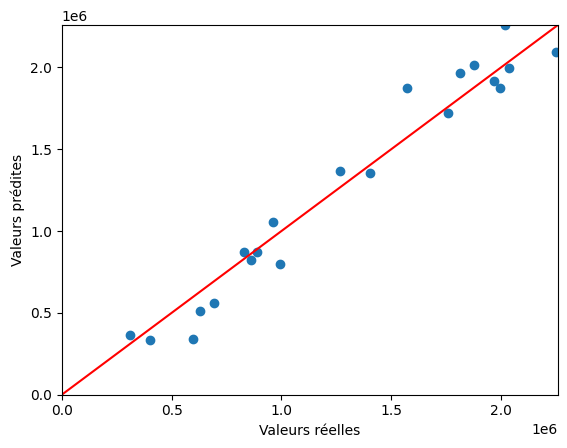

In [27]:
lim_max = max(y_test.max(), y_test_pred.max())

plt.scatter(y_test, y_test_pred)
plt.plot([0, lim_max], [0, lim_max], color="red")
plt.xlim(0, lim_max)
plt.ylim(0, lim_max)
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.show()

In [28]:
'''plt.scatter(y_test, y_test_pred)
plt.xlim(0)
plt.ylim(0)
plt.show()'''

'plt.scatter(y_test, y_test_pred)\nplt.xlim(0)\nplt.ylim(0)\nplt.show()'